# Лабораторная работа № 1. Основы анализа данных в R

**Вариант 7 — Stack Overflow Developer Survey 2011–2022.** Цель — загрузить и описать данные, провести корреляционный, регрессионный и дисперсионный анализ и объяснить их результаты.

Для статистических расчётов взят **опрос 2022 года**, одна волна с едиными вопросами о стаже и вознаграждении. В задании указан [архив Kaggle](https://www.kaggle.com/datasets/yasirabdaali/stack-overflow-developer-survey-20112022). Его CSV за 2022 год содержит повреждённый фрагмент, поэтому используется [исходная таблица Stack Overflow за 2022 год](https://github.com/StackExchange/Survey/tree/main/packages/archive/2022). [Описание опроса и методология](https://survey.stackoverflow.co/2022/#methodology).

Запускайте ячейки сверху вниз в ядре **R**. Для работы без интернета задайте путь к CSV в переменной окружения `ITAIOD_SURVEY_CSV` или положите файл `survey_results_public.csv` рядом с ноутбуком либо в папку `../data`.

## 1. Загрузка и описание данных

Строка исходной таблицы — один участник опроса. Для исследования выбраны следующие поля:

| Поле | Тип в анализе | Смысл |
| --- | --- | --- |
| `ResponseId` | целочисленный идентификатор | Номер ответа |
| `MainBranch` | категория | Относит ли себя участник к профессиональным разработчикам |
| `Country` | категория | Страна проживания |
| `Employment` | текст со списком категорий | Статус занятости, варианты разделены точкой с запятой |
| `YearsCodePro` | числовая переменная после обработки | Число лет профессионального программирования |
| `EdLevel` | категория | Наивысший уровень формального образования |
| `ConvertedCompYearly` | числовая переменная | Годовое вознаграждение, пересчитанное в доллары США |

In [1]:
# Загружает выбранные поля из локального или общедоступного CSV 2022 года.
# Возвращает data.frame с уникальными идентификаторами ответов.
read_survey <- function(local_path, public_url, columns) {
  if (!nzchar(local_path)) {
    local_path <- tempfile(fileext = ".csv")
    on.exit(unlink(local_path), add = TRUE)
    previous_options <- options(timeout = max(300L, getOption("timeout")))
    on.exit(options(previous_options), add = TRUE)
    download_status <- download.file(public_url, local_path, mode = "wb", quiet = TRUE)
    if (download_status != 0L) {
      stop("Не удалось загрузить CSV. Задайте ITAIOD_SURVEY_CSV.")
    }
  }
  if (!file.exists(local_path)) {
    stop("CSV не найден: ", local_path)
  }

  header <- names(read.csv(local_path, nrows = 0, check.names = FALSE))
  missing_columns <- setdiff(columns, header)
  if (length(missing_columns) > 0L) {
    stop("В таблице нет полей: ", paste(missing_columns, collapse = ", "))
  }
  column_types <- ifelse(header %in% columns, "character", "NULL")
  records <- read.csv(
    local_path,
    colClasses = column_types,
    check.names = FALSE,
    na.strings = c("", "NA"),
    encoding = "UTF-8"
  )
  if (anyNA(records$ResponseId) || anyDuplicated(records$ResponseId)) {
    stop("Идентификаторы ответов должны быть заполнены и уникальны.")
  }
  cat("Размер исходного CSV:", nrow(records), "строк и", length(header), "столбцов\n")
  records
}

local_csv <- Sys.getenv("ITAIOD_SURVEY_CSV")
if (!nzchar(local_csv)) {
  local_candidates <- c("survey_results_public.csv", "../data/survey_results_public.csv")
  local_csv <- c(local_candidates[file.exists(local_candidates)], "")[1L]
}
survey_url <- paste0(
  "https://media.githubusercontent.com/media/StackExchange/Survey/",
  "main/packages/archive/2022/results.csv"
)
columns <- c(
  "ResponseId", "MainBranch", "Country", "Employment",
  "YearsCodePro", "EdLevel", "ConvertedCompYearly"
)
survey <- read_survey(local_csv, survey_url, columns)
print(head(survey, 4L))
print(data.frame(Field = names(survey), Missing = colSums(is.na(survey))))

Размер исходного CSV: 73268 строк и 79 столбцов


  ResponseId
1          1
2          2
3          3
4          4
                                                                     MainBranch
1                                                                 None of these
2                                                I am a developer by profession
3 I am not primarily a developer, but I write code sometimes as part of my work
4                                                I am a developer by profession
           Employment                                         EdLevel
1                <NA>                                            <NA>
2 Employed, full-time                                            <NA>
3 Employed, full-time Master’s degree (M.A., M.S., M.Eng., MBA, etc.)
4 Employed, full-time    Bachelor’s degree (B.A., B.S., B.Eng., etc.)
  YearsCodePro                                              Country
1         <NA>                                                 <NA>
2         <NA>                                   

                                  Field Missing
ResponseId                   ResponseId       0
MainBranch                   MainBranch       0
Employment                   Employment    1559
EdLevel                         EdLevel    1697
YearsCodePro               YearsCodePro   21435
Country                         Country    1497
ConvertedCompYearly ConvertedCompYearly   35197


## 2. Предобработка и первичный анализ

В рабочую выборку входят профессиональные разработчики из США, указавшие полную занятость. Сравнение внутри страны уменьшает влияние различий между рынками труда. Для сравнения образования выбраны три академические ступени. Строки без валидного стажа, положительного вознаграждения или одной из трёх выбранных ступеней исключаются из общей выборки для моделей.

Значение `Less than 1 year` кодируется как 0,5 года. Верхняя открытая категория `More than 50 years` кодируется как 51 год. Для вознаграждения используется натуральный логарифм из-за сильной правой асимметрии. Таблица по группам сохраняет исходные единицы — доллары в год.

In [2]:
full_time <- grepl("(^|;)Employed, full-time(;|$)", survey$Employment)
eligible <- subset(
  survey,
  MainBranch == "I am a developer by profession" &
    Country %in% c("United States", "United States of America") & full_time
)

experience_text <- eligible$YearsCodePro
experience_text[which(experience_text == "Less than 1 year")] <- "0.5"
experience_text[which(experience_text == "More than 50 years")] <- "51"

education_levels <- c(
  "Bachelor\u2019s degree (B.A., B.S., B.Eng., etc.)",
  "Master\u2019s degree (M.A., M.S., M.Eng., MBA, etc.)",
  "Other doctoral degree (Ph.D., Ed.D., etc.)"
)
prepared <- data.frame(
  experience = as.numeric(experience_text),
  salary = as.numeric(eligible$ConvertedCompYearly),
  education = factor(
    eligible$EdLevel, levels = education_levels,
    labels = c("Bachelor", "Master", "Doctorate")
  )
)
analysis_data <- subset(
  prepared,
  is.finite(experience) & experience >= 0 &
    is.finite(salary) & salary > 0 & !is.na(education)
)
analysis_data$log_salary <- log(analysis_data$salary)

print(data.frame(
  Stage = c("Исходный CSV", "США, профессионалы с полной занятостью", "Выборка моделей"),
  Rows = c(nrow(survey), nrow(eligible), nrow(analysis_data))
))
print(summary(analysis_data[c("experience", "salary")]))
print(aggregate(
  salary ~ education, data = analysis_data,
  FUN = function(x) c(n = length(x), median_USD = median(x), mean_USD = mean(x))
), row.names = FALSE)

                                   Stage  Rows
1                           Исходный CSV 73268
2 США, профессионалы с полной занятостью  9133
3                        Выборка моделей  6161


   experience        salary        
 Min.   : 0.50   Min.   :      49  
 1st Qu.: 4.00   1st Qu.:  110000  
 Median : 8.00   Median :  150000  
 Mean   :11.13   Mean   :  385986  
 3rd Qu.:15.00   3rd Qu.:  200000  
 Max.   :51.00   Max.   :35000000  


 education salary.n salary.median_USD salary.mean_USD
  Bachelor   4511.0          140000.0        383864.4
    Master   1425.0          160000.0        381526.4
 Doctorate    225.0          170000.0        456752.9


## 3. Корреляционный анализ

Проверяем нулевую гипотезу об отсутствии связи стажа с логарифмом вознаграждения. Коэффициент Пирсона описывает линейную связь, коэффициент Спирмена — монотонную. Для Пирсона выводится 95%-й доверительный интервал.


	Pearson's product-moment correlation

data:  experience and log_salary
t = 8.4674, df = 6159, p-value < 2.2e-16
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.08252032 0.13188823
sample estimates:
      cor 
0.1072704 




	Spearman's rank correlation rho

data:  experience and log_salary
S = 2.6309e+10, p-value < 2.2e-16
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.3250126 



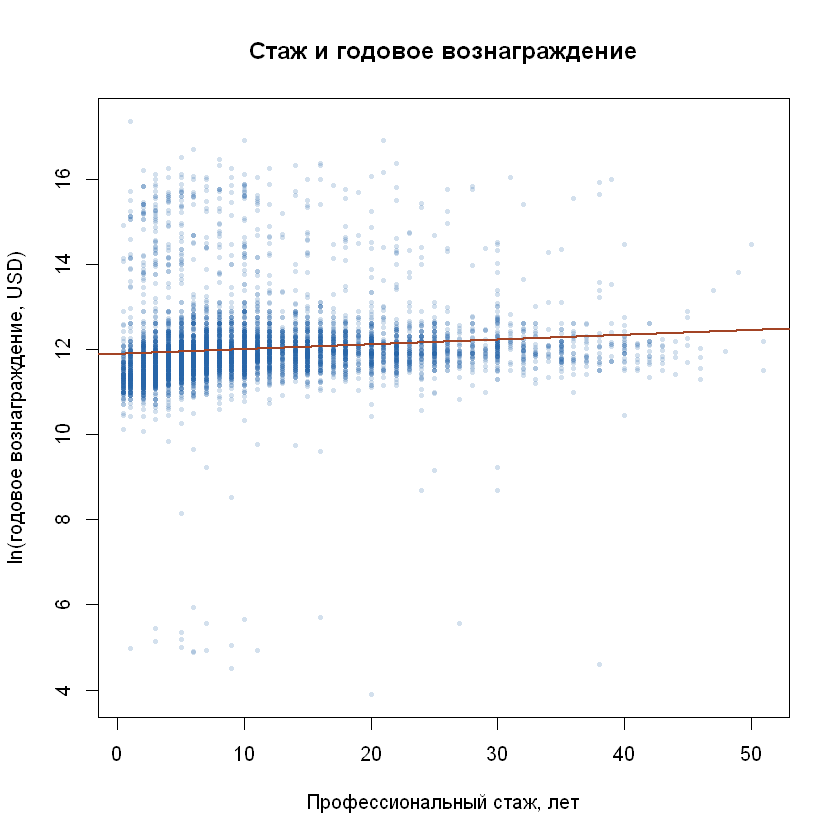

In [3]:
pearson <- with(analysis_data, cor.test(experience, log_salary, method = "pearson"))
spearman <- with(
  analysis_data,
  cor.test(experience, log_salary, method = "spearman", exact = FALSE)
)
print(pearson)
print(spearman)

plot(
  log_salary ~ experience, data = analysis_data,
  pch = 16, cex = 0.55, col = adjustcolor("#2563A6", alpha.f = 0.20),
  main = "Стаж и годовое вознаграждение", xlab = "Профессиональный стаж, лет",
  ylab = "ln(годовое вознаграждение, USD)"
)
simple_model <- lm(log_salary ~ experience, data = analysis_data)
abline(simple_model, col = "#A34425", lwd = 2)

## 4. Регрессионный анализ

Парная модель использует профессиональный стаж. В множественную добавляется уровень образования с бакалавриатом в качестве базовой категории.

$$
\log(Y_i) = \beta_0 + \beta_1 x_i
  + \beta_2 I(\text{Master}_i)
  + \beta_3 I(\text{Doctorate}_i) + \varepsilon_i.
$$

Коэффициент $\beta_1$ показывает изменение логарифма вознаграждения при увеличении стажа на год при фиксированном уровне образования. В исходной шкале это множитель $e^{\beta_1}$. Сравнение вложенных моделей проводится на одних и тех же наблюдениях.


Call:
lm(formula = log_salary ~ experience, data = analysis_data)

Residuals:
    Min      1Q  Median      3Q     Max 
-8.2329 -0.4230 -0.1451  0.1585  5.4572 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 11.902597   0.018854 631.306   <2e-16 ***
experience   0.011104   0.001311   8.467   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.9373 on 6159 degrees of freedom
Multiple R-squared:  0.01151,	Adjusted R-squared:  0.01135 
F-statistic:  71.7 on 1 and 6159 DF,  p-value: < 2.2e-16




Call:
lm(formula = log_salary ~ experience + education, data = analysis_data)

Residuals:
    Min      1Q  Median      3Q     Max 
-8.2007 -0.4196 -0.1488  0.1590  5.4783 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)        11.881990   0.019637 605.092  < 2e-16 ***
experience          0.010526   0.001319   7.980 1.73e-15 ***
educationMaster     0.091529   0.028623   3.198  0.00139 ** 
educationDoctorate  0.160612   0.064052   2.508  0.01218 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.9363 on 6157 degrees of freedom
Multiple R-squared:  0.01389,	Adjusted R-squared:  0.01341 
F-statistic: 28.92 on 3 and 6157 DF,  p-value: < 2.2e-16



Analysis of Variance Table

Model 1: log_salary ~ experience
Model 2: log_salary ~ experience + education
  Res.Df    RSS Df Sum of Sq      F    Pr(>F)    
1   6159 5410.9                                  
2   6157 5397.9  2    13.068 7.4531 0.0005849 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


                   Estimate 2.5 % 97.5 %
experience             1.06  0.80   1.32
educationMaster        9.58  3.61  15.91
educationDoctorate    17.42  3.57  33.13


  experience education
1          8  Bachelor


      fit      lwr      upr
1 11.9662 11.93812 11.99427
1 11.9662 10.13046 13.80194


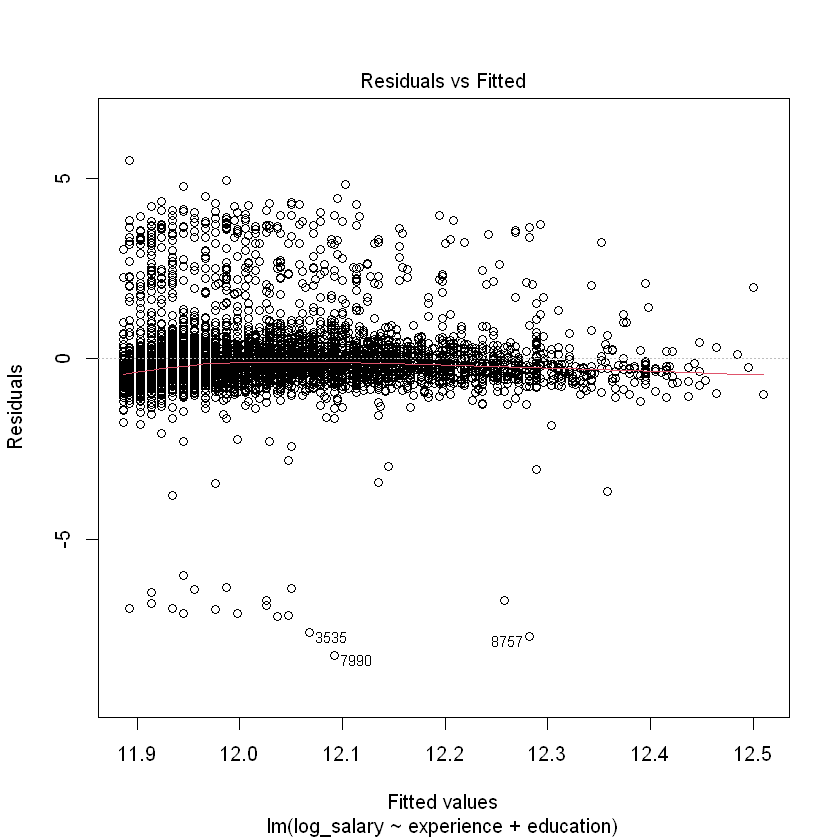

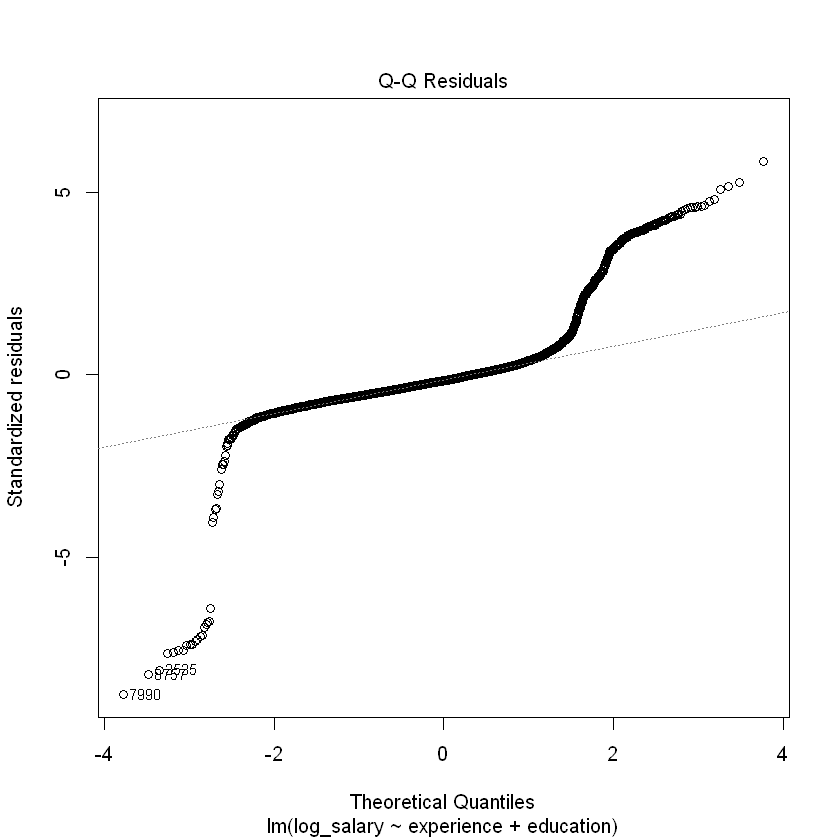

In [4]:
adjusted_model <- lm(log_salary ~ experience + education, data = analysis_data)
print(summary(simple_model))
print(summary(adjusted_model))
print(anova(simple_model, adjusted_model))

percent_effects <- 100 * (exp(cbind(
  Estimate = coef(adjusted_model),
  confint(adjusted_model)
)) - 1)
print(round(percent_effects[-1L, , drop = FALSE], 2L))

typical_profile <- data.frame(
  experience = median(analysis_data$experience),
  education = "Bachelor"
)
print(typical_profile)
print(rbind(
  mean_log = predict(adjusted_model, newdata = typical_profile, interval = "confidence"),
  individual_log = predict(adjusted_model, newdata = typical_profile, interval = "prediction")
))

plot(adjusted_model, which = 1)
plot(adjusted_model, which = 2)

Интервалы выше показаны на логарифмической шкале. Первый относится к среднему отклику для указанного профиля, второй — к отдельному участнику и включает остаточную вариацию. График остатков помогает заметить нелинейность и неодинаковый разброс, Q–Q-график показывает отклонение от нормальности в хвостах.

## 5. Дисперсионный анализ

Однофакторный ANOVA проверяет равенство средних логарифмов вознаграждения между тремя образовательными группами без поправки на стаж. Тест Уэлча проверяет ту же гипотезу без предположения о равных дисперсиях. Сравнение вложенных регрессий из предыдущего раздела учитывает стаж.

              Df Sum Sq Mean Sq F value   Pr(>F)    
education      2     20  10.111   11.42 1.12e-05 ***
Residuals   6158   5454   0.886                     
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1



	One-way analysis of means (not assuming equal variances)

data:  log_salary and education
F = 11.573, num df = 2.00, denom df = 584.51, p-value = 1.178e-05



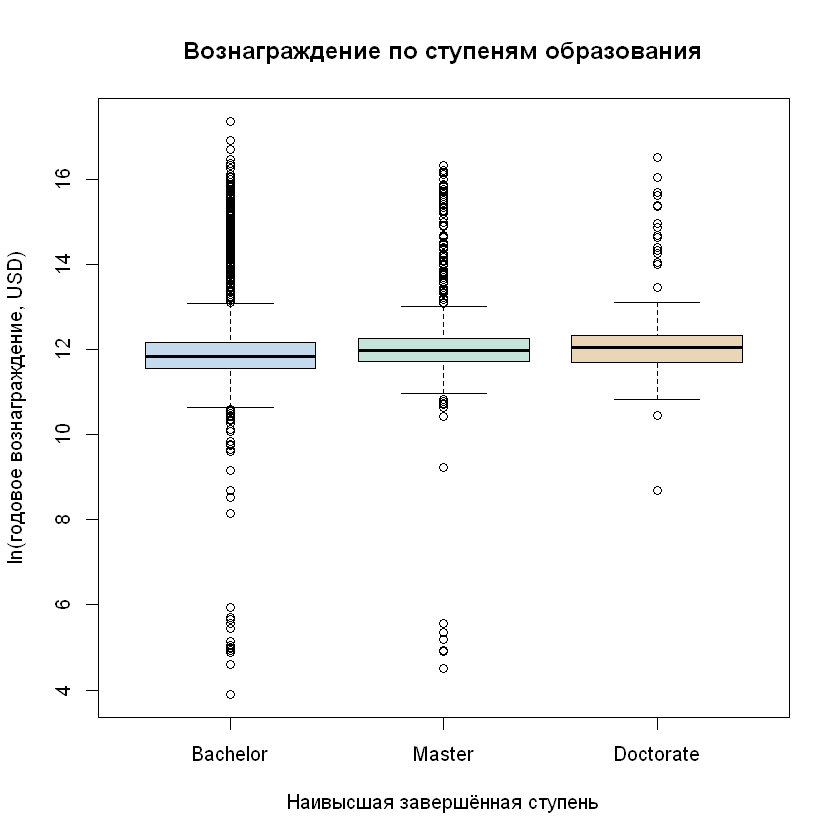

In [5]:
education_anova <- aov(log_salary ~ education, data = analysis_data)
welch <- oneway.test(log_salary ~ education, data = analysis_data, var.equal = FALSE)
print(summary(education_anova))
print(welch)

boxplot(
  log_salary ~ education, data = analysis_data,
  col = c("#C4DBEE", "#C3E5DA", "#EAD6B6"),
  main = "Вознаграждение по ступеням образования",
  xlab = "Наивысшая завершённая ступень",
  ylab = "ln(годовое вознаграждение, USD)"
)

## Выводы

In [6]:
model_summary <- summary(adjusted_model)
education_test <- anova(simple_model, adjusted_model)
experience_effect <- 100 * expm1(coef(adjusted_model)[["experience"]])
cat(sprintf(
  paste0(
    "Выборка содержит %d разработчиков. Корреляция стажа с логарифмом оплаты ",
    "по Пирсону равна %.3f, по Спирмену — %.3f.\n",
    "При одинаковой ступени образования один дополнительный год стажа ",
    "связан с изменением типичного вознаграждения по модели на %+.2f%%.\n",
    "Модель объясняет %.1f%% разброса логарифма вознаграждения.\n",
    "p теста Уэлча для образования без учёта стажа: %s. ",
    "p F-теста для добавления образования к стажу: %s.\n"
  ),
  nrow(analysis_data), unname(pearson$estimate), unname(spearman$estimate),
  experience_effect, 100 * model_summary$r.squared,
  format.pval(welch$p.value, digits = 3L),
  format.pval(education_test[2L, "Pr(>F)"], digits = 3L)
))

Выборка содержит 6161 разработчиков. Корреляция стажа с логарифмом оплаты по Пирсону равна 0.107, по Спирмену — 0.325.
При одинаковой ступени образования один дополнительный год стажа связан с изменением типичного вознаграждения по модели на +1.06%.
Модель объясняет 1.4% разброса логарифма вознаграждения.
p теста Уэлча для образования без учёта стажа: 1.18e-05. p F-теста для добавления образования к стажу: 0.000585.


Связь стажа с оплатой положительна. Коэффициент Пирсона указывает на слабую линейную связь, а более высокий коэффициент Спирмена — на более заметную монотонную связь. Средние логарифмы вознаграждения различаются между образовательными группами по тесту Уэлча при уровне значимости 0,05. Добавление образования к стажу статистически значимо по F-тесту, но объяснённая доля разброса остаётся небольшой.

В данных есть крайние значения годового вознаграждения. Логарифм уменьшает их влияние, а остатки в хвостах всё равно отклоняются от нормального распределения. Опрос добровольный, а расчёты используют только ответы с указанным вознаграждением и заданными характеристиками. Оценки описывают связь в выбранной подгруппе. На вознаграждение также могут влиять должность, регион внутри США и компания, поэтому коэффициент стажа сам по себе не даёт причинной оценки.